<a href="https://colab.research.google.com/github/dramaticforyouenjoy-sudo/RIT-Trading-Competition-2026/blob/main/Moving%20Average%20Crossover%20Strategy.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [29]:
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
!pip install pandas-ta-classic -q
import pandas_ta_classic as ta

import warnings
warnings.filterwarnings("ignore")

chosenticker = input("Put in a ticker: ")

df = yf.download(chosenticker,start="2025-01-01",end="2026-06-06",multi_level_index=False,progress=False,auto_adjust=True)

df['20MA']= df.ta.sma(length=20,append=True,col_names=("SMA_Fast",))
df['50MA'] = df.ta.sma(length=50,append=False,col_names=("SMA_Slow",))

df['signal'] = 0
df.loc[df['20MA'] > df['50MA'], 'signal'] = 1
df.loc[df['20MA'] < df['50MA'], 'signal'] = -1

df['position'] = df['signal'].diff()

buy_signals = df[df['position'] == 2]
sell_signals = df[df['position'] == -2]

plt.figure(figsize=(10,5))
plt.plot(df.index,df['Close'],label=str(chosenticker),color='blue')
plt.plot(df.index,df['20MA'],label='20MA',color='red')
plt.plot(df.index,df['50MA'],label='50MA',color='orange')
plt.xlabel(chosenticker,fontsize=10)
plt.ylabel("Price",fontsize=10)
plt.legend(loc='upper left',title='legend',fontsize=9)

plt.scatter(buy_signals.index,buy_signals['Close'], color='green',marker='^',label='Buy signal')
plt.scatter(sell_signals.index,sell_signals['Close'],color='red',marker='v', label='Sell signal')
df.dropna()
plt.show()

df.tail(200)

KeyboardInterrupt: 

Please input your ticker here: WMT
Loading!


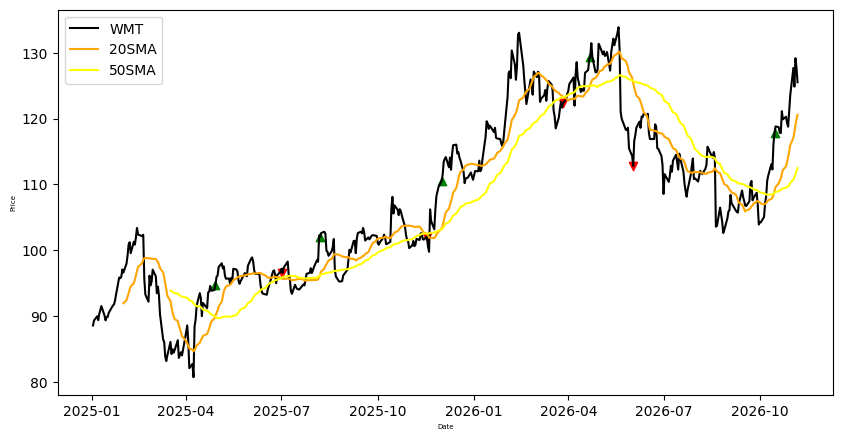

,Close,High,Low,Open,Volume,20SMA,50SMA,Signal,signal,position
Date,,,,,,,,,,
2025-08-29,96.170296,96.219874,95.000147,95.297638,15600300,99.016315,97.082629,0,1.0,0.0
2025-09-02,97.033020,97.033020,95.704212,96.418201,15351300,98.941547,97.121382,0,1.0,0.0
2025-09-03,98.609749,98.609749,96.685944,97.033020,18995900,98.959467,97.157043,0,1.0,0.0
2025-09-04,100.087303,100.503795,98.817992,99.075823,15640900,98.850922,97.219683,0,1.0,0.0
2025-09-05,99.670815,100.632717,98.718831,100.236055,13748500,98.733426,97.288635,0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...
2026-11-02,127.690002,127.940002,124.099998,124.099998,27682800,117.083000,110.713600,0,1.0,0.0
2026-11-03,124.860001,126.849998,124.550003,126.690002,21184300,117.966000,111.081000,0,1.0,0.0
2026-11-04,129.169998,130.940002,125.839996,127.000000,29284900,119.016500,111.556800,0,1.0,0.0


In [35]:
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
!pip install pandas-ta-classic -q
import pandas_ta_classic as ta

import warnings
warnings.filterwarnings("ignore")

while True:
  tickerchosen = input("Please input your ticker here: ")

  if tickerchosen.isalpha():
    print("Loading!")
    break
  else:
    print(input("Invalid, do it again: "))

df = yf.download(tickerchosen,start="2025-01-01",end="2026-12-31",multi_level_index=False,progress=False,auto_adjust=True)

df["20SMA"] = df.ta.sma(length=20,append=True,col_names=("20SMA"))
df["50SMA"] = df.ta.sma(length=50,append=True,col_names=("50SMA"))

df['Signal'] = 0

df.loc[df["20SMA"] > df["50SMA"], 'signal'] = 1
df.loc[df["20SMA"] < df["50SMA"], 'signal'] = -1

df["position"] = df['signal'].diff()

buy_signals = df[df['position'] == 2]
sell_signals = df[df['position'] == -2]



plt.figure(figsize=(10,5))
plt.plot(df.index, df['Close'], label=str(tickerchosen),color='black')

plt.plot(df.index,df['20SMA'],label="20SMA",color='orange')
plt.plot(df.index,df['50SMA'],label="50SMA",color='yellow')

plt.scatter(buy_signals.index,buy_signals['Close'],marker='^',color='green')
plt.scatter(sell_signals.index,sell_signals['Close'],marker='v',color='red')
plt.xlabel("Date",fontsize=5)
plt.ylabel("Price", fontsize=5)
plt.legend()
plt.show()
df.dropna()


df.tail(300)